In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import os

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

print("Libraries imported successfully")

Libraries imported successfully


In [2]:
df = pd.read_csv("../data/loan_dataset.csv")

print("Dataset loaded successfully")
print("Shape:", df.shape)

C:\Users\Ann Nguyen\AppData\Local\Temp\ipykernel_4436\2355820367.py:1: DtypeWarning: Columns (14: desc) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../data/loan_dataset.csv")


Dataset loaded successfully
Shape: (1347681, 15)


In [3]:
df.head()

,id,issue_d,revenue,dti_n,loan_amnt,fico_n,experience_c,emp_length,purpose,home_ownership_n,addr_state,zip_code,Default,title,desc
0,68407277,Dec-2015,55000.0,5.91,3600,677.0,1,10+ years,debt_consolidation,MORTGAGE,PA,190xx,0,Debt consolidation,NaN
1,68355089,Dec-2015,65000.0,16.06,24700,717.0,1,10+ years,small_business,MORTGAGE,SD,577xx,0,Business,NaN
2,68341763,Dec-2015,71000.0,13.85,20000,697.0,1,10+ years,home_improvement,MORTGAGE,IL,605xx,0,NaN,NaN
3,68476807,Dec-2015,104433.0,25.37,10400,697.0,1,3 years,major_purchase,MORTGAGE,PA,174xx,0,Major purchase,NaN
4,68426831,Dec-2015,34000.0,10.20,11950,692.0,1,4 years,debt_consolidation,RENT,GA,300xx,0,Debt consolidation,NaN


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1347681 entries, 0 to 1347680
Data columns (total 15 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   id                1347681 non-null  int64  
 1   issue_d           1347681 non-null  str    
 2   revenue           1347681 non-null  float64
 3   dti_n             1347681 non-null  float64
 4   loan_amnt         1347681 non-null  int64  
 5   fico_n            1347681 non-null  float64
 6   experience_c      1347681 non-null  int64  
 7   emp_length        1347681 non-null  str    
 8   purpose           1347681 non-null  str    
 9   home_ownership_n  1347681 non-null  str    
 10  addr_state        1347681 non-null  str    
 11  zip_code          1347680 non-null  str    
 12  Default           1347681 non-null  int64  
 13  title             1331024 non-null  str    
 14  desc              119099 non-null   str    
dtypes: float64(3), int64(4), str(8)
memory usage: 154.2 MB


In [5]:
df.columns.tolist()

['id',
 'issue_d',
 'revenue',
 'dti_n',
 'loan_amnt',
 'fico_n',
 'experience_c',
 'emp_length',
 'purpose',
 'home_ownership_n',
 'addr_state',
 'zip_code',
 'Default',
 'title',
 'desc']

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,1347681.0,5.621359e+07,3.839501e+07,54734.0,19706506.00,57664225.00,84495046.00,145636374.0
revenue,1347681.0,7.736968e+04,7.036299e+04,1896.0,46600.00,65000.00,92000.00,10999200.0
dti_n,1347681.0,1.829909e+01,1.115214e+01,0.0,11.82,17.63,24.07,999.0
loan_amnt,1347681.0,1.440823e+04,8.715347e+03,500.0,7975.00,12000.00,20000.00,40000.0
fico_n,1347681.0,6.981589e+02,3.184872e+01,612.0,672.00,692.00,712.00,847.5
experience_c,1347681.0,9.999814e-01,4.306977e-03,0.0,1.00,1.00,1.00,1.0
Default,1347681.0,1.997869e-01,3.998402e-01,0.0,0.00,0.00,0.00,1.0


In [7]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 1347681
Columns: 15


In [8]:
df["Default"].value_counts()

Default
0    1078432
1     269249
Name: count, dtype: int64

In [9]:
df["Default"].value_counts(normalize=True) * 100

Default
0    80.021311
1    19.978689
Name: proportion, dtype: float64

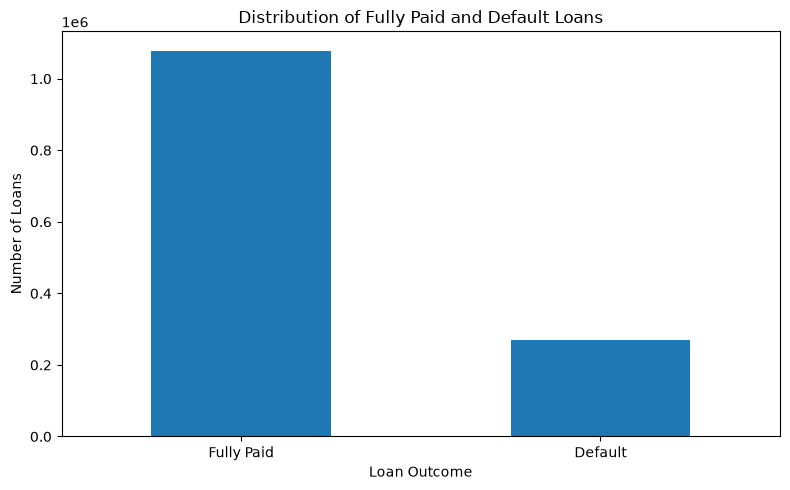

In [10]:
target_counts = (
    df["Default"]
    .value_counts()
    .sort_index()
)

target_counts.index = [
    "Fully Paid",
    "Default"
]

plt.figure(figsize=(8, 5))

target_counts.plot(kind="bar")

plt.title(
    "Distribution of Fully Paid and Default Loans"
)

plt.xlabel("Loan Outcome")
plt.ylabel("Number of Loans")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [11]:
missing_values = (
    df.isnull()
    .sum()
    .sort_values(
        ascending=False
    )
)

missing_values[
    missing_values > 0
]

desc        1228582
title         16657
zip_code          1
dtype: int64

In [12]:
missing_percentage = (
    df.isnull().mean()
    * 100
)

missing_percentage = (
    missing_percentage
    .sort_values(
        ascending=False
    )
)

missing_percentage[
    missing_percentage > 0
]

desc        91.162671
title        1.235975
zip_code     0.000074
dtype: float64

In [13]:
missing_table = pd.DataFrame({
    "Missing Values":
        df.isnull().sum(),

    "Percentage":
        df.isnull().mean() * 100
})

missing_table = missing_table[
    missing_table["Missing Values"] > 0
]

missing_table = (
    missing_table
    .sort_values(
        "Percentage",
        ascending=False
    )
)

missing_table

,Missing Values,Percentage
desc,1228582,91.162671
title,16657,1.235975
zip_code,1,0.000074


In [14]:
duplicate_count = (
    df.duplicated().sum()
)

print(
    "Duplicate rows:",
    duplicate_count
)

Duplicate rows: 0


In [15]:
df["revenue"].describe()

count    1.347681e+06
mean     7.736968e+04
std      7.036299e+04
min      1.896000e+03
25%      4.660000e+04
50%      6.500000e+04
75%      9.200000e+04
max      1.099920e+07
Name: revenue, dtype: float64

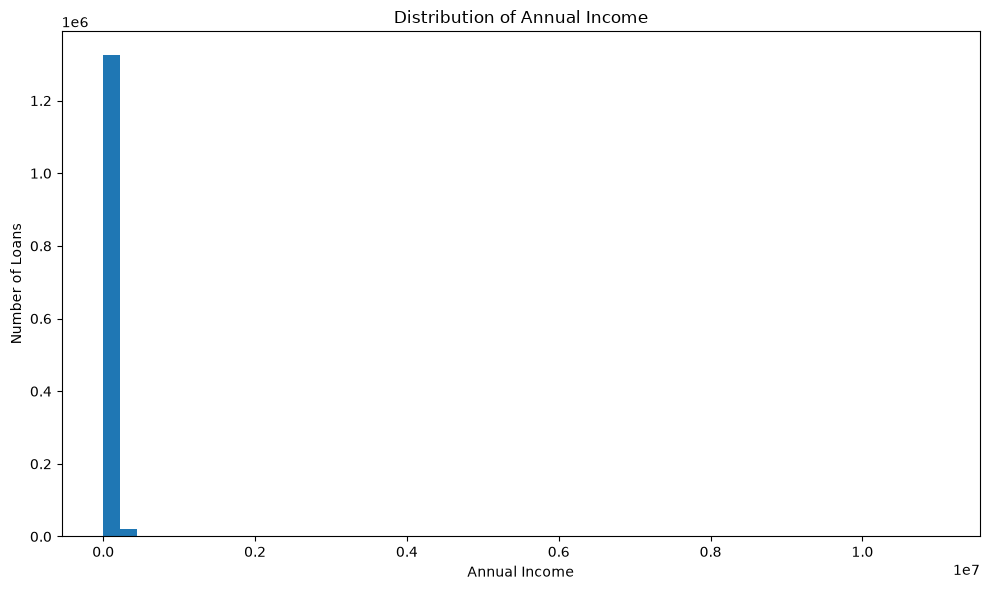

In [16]:
plt.figure(figsize=(10, 6))

plt.hist(
    df["revenue"].dropna(),
    bins=50
)

plt.title(
    "Distribution of Annual Income"
)

plt.xlabel("Annual Income")
plt.ylabel("Number of Loans")

plt.tight_layout()
plt.show()

In [17]:
df["dti_n"].describe()

count    1.347681e+06
mean     1.829909e+01
std      1.115214e+01
min      0.000000e+00
25%      1.182000e+01
50%      1.763000e+01
75%      2.407000e+01
max      9.990000e+02
Name: dti_n, dtype: float64

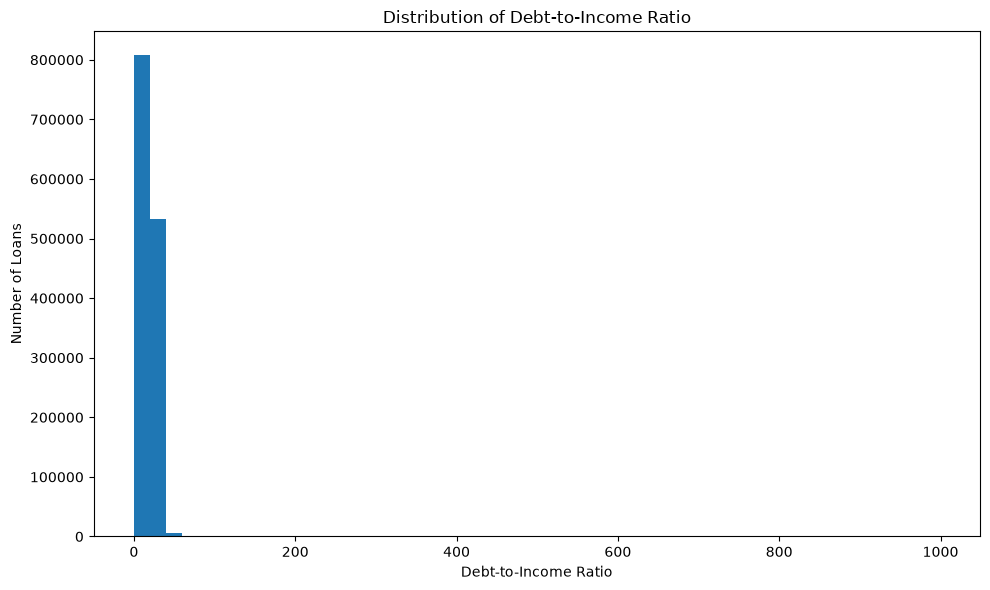

In [18]:
plt.figure(figsize=(10, 6))

plt.hist(
    df["dti_n"].dropna(),
    bins=50
)

plt.title(
    "Distribution of Debt-to-Income Ratio"
)

plt.xlabel(
    "Debt-to-Income Ratio"
)

plt.ylabel(
    "Number of Loans"
)

plt.tight_layout()
plt.show()

In [19]:
Q1 = df["revenue"].quantile(0.25)

Q3 = df["revenue"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = (
    Q1 - 1.5 * IQR
)

upper_bound = (
    Q3 + 1.5 * IQR
)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print(
    "Lower bound:",
    lower_bound
)

print(
    "Upper bound:",
    upper_bound
)

Q1: 46600.0
Q3: 92000.0
IQR: 45400.0
Lower bound: -21500.0
Upper bound: 160100.0


In [20]:
revenue_outliers = df[
    (df["revenue"] < lower_bound)
    |
    (df["revenue"] > upper_bound)
]

print(
    "Potential outliers:",
    len(revenue_outliers)
)

print(
    "Percentage:",
    len(revenue_outliers)
    / len(df)
    * 100
)

Potential outliers: 62998
Percentage: 4.6745483538018275


C:\Users\Ann Nguyen\AppData\Local\Temp\ipykernel_4436\140715310.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


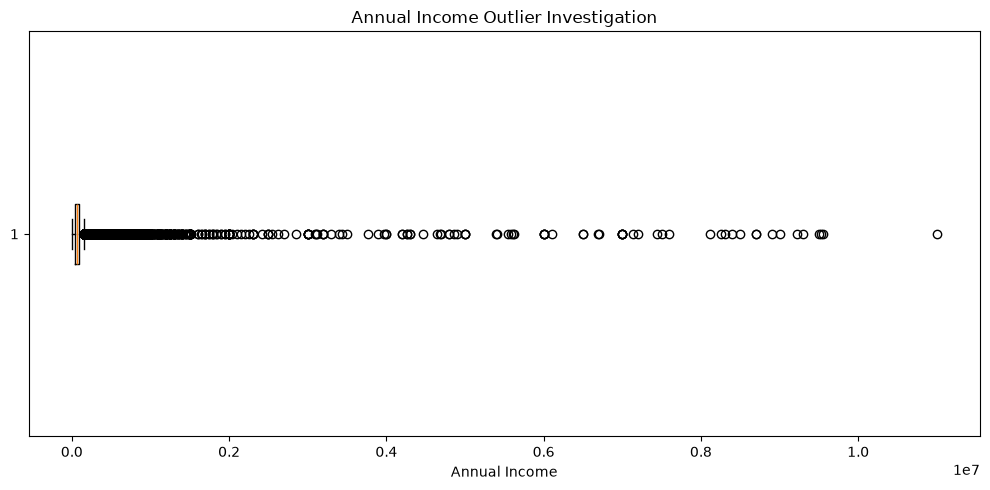

In [21]:
plt.figure(figsize=(10, 5))

plt.boxplot(
    df["revenue"].dropna(),
    vert=False
)

plt.title(
    "Annual Income Outlier Investigation"
)

plt.xlabel(
    "Annual Income"
)

plt.tight_layout()
plt.show()

In [22]:
clean_df = df.copy()

print(
    "Working dataset:",
    clean_df.shape
)

Working dataset: (1347681, 15)


In [23]:
features = [
    "revenue",
    "dti_n"
]


for column in features:

    median_value = (
        clean_df[column]
        .median()
    )

    clean_df[column] = (
        clean_df[column]
        .fillna(
            median_value
        )
    )

    print(
        column,
        "median:",
        median_value
    )

revenue median: 65000.0
dti_n median: 17.63


In [24]:
clean_df[
    [
        "revenue",
        "dti_n"
    ]
].isnull().sum()

revenue    0
dti_n      0
dtype: int64

In [25]:
print(
    "Missing target values:",
    clean_df["Default"]
    .isnull()
    .sum()
)

Missing target values: 0


In [26]:
features = [
    "revenue",
    "dti_n"
]

target = "Default"


X = clean_df[
    features
].copy()

y = clean_df[
    target
].copy()


print(
    "X shape:",
    X.shape
)

print(
    "y shape:",
    y.shape
)

X shape: (1347681, 2)
y shape: (1347681,)


In [27]:
print(
    "Missing X:"
)

print(
    X.isnull().sum()
)


print(
    "\nMissing y:",
    y.isnull().sum()
)

Missing X:
revenue    0
dti_n      0
dtype: int64

Missing y: 0


In [28]:
X_train, X_test, y_train, y_test = (
    train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )
)


print(
    "Training samples:",
    X_train.shape[0]
)

print(
    "Testing samples:",
    X_test.shape[0]
)

Training samples: 1078144
Testing samples: 269537


In [29]:
print(
    "Training:"
)

print(
    y_train.value_counts(
        normalize=True
    )
)


print(
    "\nTesting:"
)

print(
    y_test.value_counts(
        normalize=True
    )
)

Training:
Default
0    0.800213
1    0.199787
Name: proportion, dtype: float64

Testing:
Default
0    0.800213
1    0.199787
Name: proportion, dtype: float64


In [30]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [31]:
model.fit(
    X_train,
    y_train
)

print(
    "Random Forest trained successfully"
)

Random Forest trained successfully


In [32]:
y_pred = model.predict(
    X_test
)

y_probability = (
    model.predict_proba(
        X_test
    )[:, 1]
)

print(
    "Predictions completed"
)

Predictions completed


In [33]:
print(
    "Model classes:",
    model.classes_
)

Model classes: [0 1]


In [34]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_probability
)


print(
    f"Accuracy:  {accuracy:.4f}"
)

print(
    f"Precision: {precision:.4f}"
)

print(
    f"Recall:    {recall:.4f}"
)

print(
    f"F1-score:  {f1:.4f}"
)

print(
    f"ROC-AUC:   {roc_auc:.4f}"
)

Accuracy:  0.7618
Precision: 0.2214
Recall:    0.0764
F1-score:  0.1136
ROC-AUC:   0.5261


In [35]:
results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],

    "Result": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

results

,Metric,Result
0,Accuracy,0.761806
1,Precision,0.221361
2,Recall,0.076360
3,F1-score,0.113550
4,ROC-AUC,0.526076


In [36]:
print(
    classification_report(
        y_test,
        y_pred,

        target_names=[
            "Fully Paid",
            "Default"
        ],

        zero_division=0
    )
)

              precision    recall  f1-score   support

  Fully Paid       0.80      0.93      0.86    215687
     Default       0.22      0.08      0.11     53850

    accuracy                           0.76    269537
   macro avg       0.51      0.50      0.49    269537
weighted avg       0.69      0.76      0.71    269537



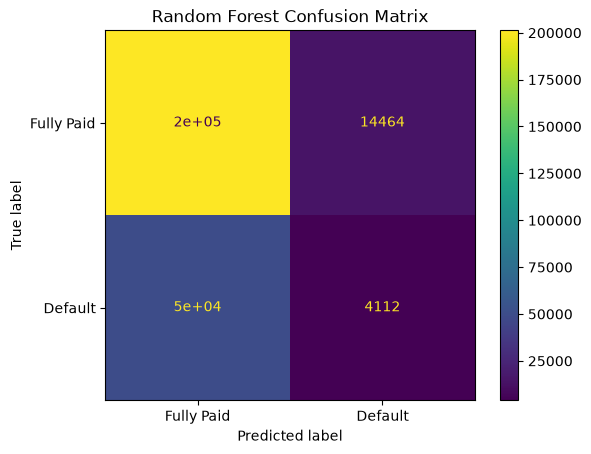

In [37]:
cm = confusion_matrix(
    y_test,
    y_pred
)


display = ConfusionMatrixDisplay(
    confusion_matrix=cm,

    display_labels=[
        "Fully Paid",
        "Default"
    ]
)


display.plot()

plt.title(
    "Random Forest Confusion Matrix"
)

plt.show()

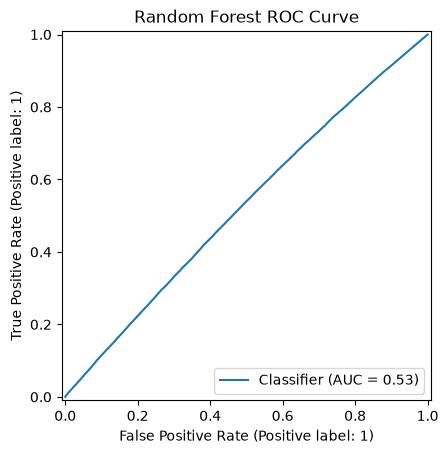

In [38]:
RocCurveDisplay.from_predictions(
    y_test,
    y_probability
)

plt.title(
    "Random Forest ROC Curve"
)

plt.show()

In [39]:
feature_importance = pd.DataFrame({
    "Feature":
        features,

    "Importance":
        model.feature_importances_
})


feature_importance = (
    feature_importance
    .sort_values(
        "Importance",
        ascending=False
    )
)

feature_importance

,Feature,Importance
1,dti_n,0.583816
0,revenue,0.416184


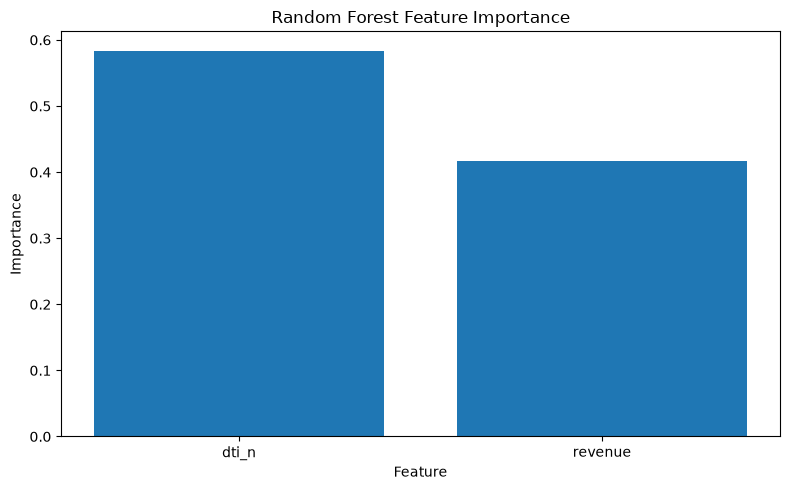

In [40]:
plt.figure(figsize=(8, 5))

plt.bar(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.title(
    "Random Forest Feature Importance"
)

plt.xlabel("Feature")
plt.ylabel("Importance")

plt.tight_layout()
plt.show()

In [41]:
applicant = pd.DataFrame({
    "revenue": [
        60000
    ],

    "dti_n": [
        20
    ]
})

applicant

,revenue,dti_n
0,60000,20


In [42]:
prediction = model.predict(
    applicant
)[0]


probabilities = (
    model.predict_proba(
        applicant
    )[0]
)


print(
    "Prediction:",
    prediction
)

print(
    "Probabilities:",
    probabilities
)

print(
    "Classes:",
    model.classes_
)
prediction = model.predict(
    applicant
)[0]


probabilities = (
    model.predict_proba(
        applicant
    )[0]
)


print(
    "Prediction:",
    prediction
)

print(
    "Probabilities:",
    probabilities
)

print(
    "Classes:",
    model.classes_
)

Prediction: 0
Probabilities: [0.82615873 0.17384127]
Classes: [0 1]
Prediction: 0
Probabilities: [0.82615873 0.17384127]
Classes: [0 1]


In [43]:
classes = list(
    model.classes_
)


repayment_index = (
    classes.index(0)
)

default_index = (
    classes.index(1)
)


repayment_probability = (
    probabilities[
        repayment_index
    ] * 100
)


default_probability = (
    probabilities[
        default_index
    ] * 100
)


print(
    f"Repayment: "
    f"{repayment_probability:.2f}%"
)

print(
    f"Default: "
    f"{default_probability:.2f}%"
)

Repayment: 82.62%
Default: 17.38%


In [44]:
if prediction == 0:

    outcome = (
        "LIKELY TO REPAY"
    )

else:

    outcome = (
        "LIKELY TO DEFAULT"
    )


print(
    "LOAN REPAYMENT ASSESSMENT"
)

print(
    "-------------------------"
)

print(
    "Predicted Outcome:",
    outcome
)

print(
    f"Repayment Probability: "
    f"{repayment_probability:.2f}%"
)

print(
    f"Default Probability: "
    f"{default_probability:.2f}%"
)

LOAN REPAYMENT ASSESSMENT
-------------------------
Predicted Outcome: LIKELY TO REPAY
Repayment Probability: 82.62%
Default Probability: 17.38%


In [45]:
def predict_loan(
    annual_income,
    dti
):

    if annual_income < 0:

        raise ValueError(
            "Annual income cannot be negative."
        )


    if dti < 0:

        raise ValueError(
            "DTI cannot be negative."
        )


    applicant = pd.DataFrame({
        "revenue": [
            annual_income
        ],

        "dti_n": [
            dti
        ]
    })


    prediction = model.predict(
        applicant
    )[0]


    probabilities = (
        model.predict_proba(
            applicant
        )[0]
    )


    classes = list(
        model.classes_
    )


    repayment_probability = (
        probabilities[
            classes.index(0)
        ] * 100
    )


    default_probability = (
        probabilities[
            classes.index(1)
        ] * 100
    )


    if prediction == 0:

        outcome = (
            "LIKELY TO REPAY"
        )

    else:

        outcome = (
            "LIKELY TO DEFAULT"
        )


    return {

        "prediction":
            int(prediction),

        "outcome":
            outcome,

        "repayment_probability":
            round(
                float(
                    repayment_probability
                ),
                2
            ),

        "default_probability":
            round(
                float(
                    default_probability
                ),
                2
            )
    }

In [46]:
result = predict_loan(
    annual_income=60000,
    dti=20
)

result

{'prediction': 0,
 'outcome': 'LIKELY TO REPAY',
 'repayment_probability': 82.62,
 'default_probability': 17.38}

In [47]:
os.makedirs(
    "../models",
    exist_ok=True
)


model_path = (
    "../models/random_forest_model.pkl"
)


joblib.dump(
    model,
    model_path
)


print(
    "Model saved to:",
    model_path
)

Model saved to: ../models/random_forest_model.pkl


In [48]:
loaded_model = joblib.load(
    "../models/random_forest_model.pkl"
)


print(
    "Model loaded successfully"
)

print(
    "Classes:",
    loaded_model.classes_
)

print(
    "Features:",
    loaded_model.feature_names_in_
)

Model loaded successfully
Classes: [0 1]
Features: ['revenue' 'dti_n']
